# **2) Build and Test Model**

Purpose: Get pretrained ConvNeXt model, create new classification layer, perform cross validation and test model

Languages: Python 3

IDE: Google Colab, file is a Jupiter Notebook notebook document (.ipynb)

Inputs: cleaned_aic_paintings_colab.csv

Outputs: train_split.csv, test_split.csv, final_train_history.csv, test_metrics.json, classification_report.txt, confusion_matrix.csv, confusion_matrix.png, test_predictions.csv, convnext_art_movement.pt,
gradcam.png, cv_fold1_history.csv, cv_fold2_history.csv, cv_fold3_history.csv, cv_fold4_history.csv, cv_fold5_history.csv, cv_results

Packages: torch, torchvision, timm, pandas, numpy, matplotlib, sci-kit learn, requests, pillow, shutil

Run: python SCRIPTS/1_Cleaning_EDA_Script.ipynb (from the repo root) first. Then this script.

Order: Run second

## 1. Setup

In [1]:
# install libraries
# timm contains pretrained ConvNeXt model
!pip install -q timm scikit-learn pandas matplotlib requests pillow

In [2]:
# clone repo to get dataset
! git clone https://github.com/oliviapang/DS4002_Project_3

Cloning into 'DS4002_Project_3'...
remote: Enumerating objects: 33, done.
remote: Counting objects: 100% (33/33), done.
remote: Compressing objects: 100% (29/29), done.
remote: Total 33 (delta 7), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (33/33), 383.89 KiB | 1.44 MiB/s, done.
Resolving deltas: 100% (7/7), done.


In [3]:
# import various necessary packages
import argparse, json, math, random, time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import timm
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import Image as IPyImage, display
from PIL import Image
from sklearn.metrics import (balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score)
from sklearn.model_selection import StratifiedKFold, train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms as T

# values ConvNeXt model needs to normalize images
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
# success metric for project
FINISH_LINE = 0.85

## 2. Configuration
Edit the values below. For a quick CPU smoke test use `max_rows=150`, `model='convnext_atto.d2_in1k'`, `img_size=128`, `head_epochs=1`, `ft_epochs=1`.

In [4]:
# contains all adjustable parameters for model
args = argparse.Namespace(
    # data
    csv="DS4002_Project_3/DATA/cleaned_aic_paintings_colab.csv", # cleaned dataset
    image_root=".",          # local_path in the CSV is resolved relative to this folder
    out_dir="outputs",
    min_count=15,            # drop movements with fewer paintings than this value
    test_size=0.20,          # test set proportion
    max_rows=None,           # debug: subsample rows if only want to test on a small set of images
    skip_download=False,     # True = never download missing images
    # model
    model="convnext_tiny.fb_in22k_ft_in1k",
    no_pretrained=False,     # debug only
    img_size=224,            # standard image resolution
    drop_path=0.1,
    # training
    batch_size=16,           # images per optimisation step
    head_epochs=5,           # stage 1: backbone frozen
    ft_epochs=15,            # stage 2: full fine-tune
    lr_head=1e-3,
    lr_backbone=5e-5,
    weight_decay=0.05,
    label_smoothing=0.0,
    loss="ce",               # "ce" (weighted cross-entropy) or "focal"
    focal_gamma=2.0,
    class_weight_power=0.5,  # weight = (N / (K * n_c)) ** power; 1.0 = full inverse frequency
    num_workers=2,
    seed=42,
    # evaluation
    cv=True,                # True = run stratified k-fold CV on the training set first
    folds=5,
    gradcam=12,              # test images for Grad-CAM (0 to skip)
)

In [5]:
# set seed for random number generation, allowing for reproducability
def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

# select fastest hardware (usually GPU)
def get_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
        return torch.device("mps")
    print("WARNING: no GPU found, training on CPU will be slow.")
    return torch.device("cpu")

set_seed(args.seed)
device = get_device()
out = Path(args.out_dir); out.mkdir(parents=True, exist_ok=True)
print(f"Device: {device} | model: {args.model} | pretrained: {not args.no_pretrained}")

Device: cuda | model: convnext_tiny.fb_in22k_ft_in1k | pretrained: True


## 3. Data loading and preparation
Softmax classification needs one target per painting, so the **first label** is used from the provided list of styles.

In [6]:
# pull image from AIC API
def _download(url, dest, retries=3):
    dest.parent.mkdir(parents=True, exist_ok=True)
    headers = {"User-Agent": "DS4002-art-movement-classifier/1.0 (student project)"}
    for attempt in range(retries):
        try:
            r = requests.get(url, headers=headers, timeout=30)
            if r.status_code == 200 and r.content:
                dest.write_bytes(r.content)
                return True
        except requests.RequestException:
            pass
        time.sleep(1.5 * (attempt + 1))
    return False

# ensure image is readable
def _image_ok(path):
    try:
        with Image.open(path) as im:
            im.verify()
        return True
    except Exception:
        return False


def _ensure_image(args_tuple):
    path, url, allow_download = args_tuple
    if not path.exists() and allow_download and isinstance(url, str):
        _download(url, path)
    return path.exists() and _image_ok(path)

# read CSV containing cleaned data, create single label from "Style" column, dowload images
def load_dataframe(args):
    df = pd.read_csv(args.csv)
    if args.max_rows:
        df = df.sample(n=min(args.max_rows, len(df)), random_state=args.seed)

    # The cleaning notebook stores the (mapped) movements as a comma-separated
    # string with the painting's primary movement first. Single-label softmax
    # classification needs one target per painting, so we use that primary label.
    df["label"] = df["Style"].fillna("").map(lambda s: s.split(",")[0].strip())
    df = df[~df["label"].isin(["", "Unclassified"])].copy()

    # full path to each image
    root = Path(args.image_root)
    df["path"] = df["local_path"].map(lambda p: root / p)

    # download missing images
    n_missing = int((~df["path"].map(Path.exists)).sum())
    if n_missing:
        print(f"{n_missing} images not found locally." +
              ("" if args.skip_download else " Downloading from image_url ..."))
    jobs = list(zip(df["path"], df["image_url"], [not args.skip_download] * len(df)))
    with ThreadPoolExecutor(max_workers=8) as ex:
        ok = list(ex.map(_ensure_image, jobs))
    df = df[np.array(ok)].copy()
    n_bad = len(jobs) - len(df)
    if n_bad:
        print(f"Dropped {n_bad} paintings whose image is missing or unreadable.")

    # remove movements which are too rare for modeling
    counts = df["label"].value_counts()
    keep = counts[counts >= args.min_count].index
    dropped = counts[counts < args.min_count]
    if len(dropped):
        print("Dropping movements below min-count:", dict(dropped))
    df = df[df["label"].isin(keep)].reset_index(drop=True)

    # map each movement to integer
    classes = sorted(df["label"].unique())
    cls_to_idx = {c: i for i, c in enumerate(classes)}
    df["y"] = df["label"].map(cls_to_idx)
    print(f"\n{len(df)} paintings, {len(classes)} classes:")
    print(df["label"].value_counts().to_string(), "\n")
    return df, classes

In [7]:
class PaintingDataset(Dataset):
    # from PyTorch dataset, loads painting for given a row index
    def __init__(self, df, transform):
        self.paths = df["path"].tolist()
        self.y = df["y"].tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.transform(img), self.y[i]


def make_transforms(size):
    # transforms images for training and testing; for training slight changes are made so model sees
    # slightly different images for each epoch to avoid overfitting
    norm = T.Normalize(IMAGENET_MEAN, IMAGENET_STD)
    train_tf = T.Compose([
        T.RandomResizedCrop(size, scale=(0.4, 1.0), ratio=(3 / 4, 4 / 3)),
        T.RandomHorizontalFlip(),
        T.ColorJitter(brightness=0.1, contrast=0.1),  # mild: colour is a style cue
        T.ToTensor(),
        norm,
    ])
    eval_tf = T.Compose([
        T.Resize(int(size * 1.14)),
        T.CenterCrop(size),
        T.ToTensor(),
        norm,
    ])
    return train_tf, eval_tf


def make_loader(df, tf, args, shuffle):
    return DataLoader(PaintingDataset(df, tf), batch_size=args.batch_size,
                      shuffle=shuffle, num_workers=args.num_workers,
                      pin_memory=torch.cuda.is_available(),
                      drop_last=shuffle and len(df) > args.batch_size,
                      persistent_workers=args.num_workers > 0)

## 4. Model, loss, and scheduler

In [8]:
def build_model(args, num_classes):
    # create pretrained ConvNeXt model with new classification layer
    # num_classes != pretrained head size -> timm drops the old head and creates
    # a fresh randomly initialised linear layer for our movements
    return timm.create_model(args.model, pretrained=not args.no_pretrained,
                             num_classes=num_classes, drop_path_rate=args.drop_path)


# splits model parameters so stage 1 only trains our classification layer and
# stage 2 can use learning from pretrained layers
def head_and_backbone_params(model):
    head = list(model.get_classifier().parameters())
    head_ids = {id(p) for p in head}
    backbone = [p for p in model.parameters() if id(p) not in head_ids]
    return head, backbone

# freezes backbone parameters so new classification layer can be trained without
# affecting pretrained features
def set_backbone_trainable(model, trainable):
    _, backbone = head_and_backbone_params(model)
    for p in backbone:
        p.requires_grad = trainable


class FocalLoss(nn.Module):
    def __init__(self, weight=None, gamma=2.0, label_smoothing=0.0):
        super().__init__()
        self.weight, self.gamma, self.ls = weight, gamma, label_smoothing

    def forward(self, logits, target):
        ce = F.cross_entropy(logits, target, weight=self.weight, reduction="none",
                             label_smoothing=self.ls)
        pt = torch.exp(-F.cross_entropy(logits, target, reduction="none"))
        return ((1 - pt) ** self.gamma * ce).mean()

# build loss function with class weights from training set
def make_criterion(train_df, num_classes, args, device):
    counts = np.bincount(train_df["y"], minlength=num_classes).astype(float)
    w = (len(train_df) / (num_classes * np.maximum(counts, 1))) ** args.class_weight_power
    w = w / w.mean()
    weight = torch.tensor(w, dtype=torch.float32, device=device)
    if args.loss == "focal":
        return FocalLoss(weight, args.focal_gamma, args.label_smoothing)
    return nn.CrossEntropyLoss(weight=weight, label_smoothing=args.label_smoothing)

# warm-up helps avoid drastic changes to pretrained weights at the start of model training
def cosine_with_warmup(optimizer, total_steps, warmup_steps):
    def fn(step):
        if step < warmup_steps:
            return (step + 1) / max(1, warmup_steps)
        prog = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1 + math.cos(math.pi * prog))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, fn)

## 5. Training and evaluation functions
`fit` runs both stages: head-only with a frozen backbone, then full fine-tuning with a lower backbone learning rate.

In [9]:
# runs one pass overtraining data, updating model and returning mean loss
def train_epoch(model, loader, criterion, optimizer, scheduler, scaler, device, use_amp):
    model.train()
    total, n = 0.0, 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            loss = criterion(model(x), y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        total += loss.item() * len(y)
        n += len(y)
    return total / max(n, 1)


def predict(model, loader, device):
    model.eval()
    logits, ys = [], []
    with torch.no_grad():
      for x, y in loader:
          logits.append(model(x.to(device)).float().cpu())
          ys.append(y)
    return torch.cat(logits), torch.cat(ys)

# fraction of samples whose true class is among model's top k guesses
def topk_acc(logits, y, k):
    k = min(k, logits.shape[1])
    return (logits.topk(k, dim=1).indices == y[:, None]).any(1).float().mean().item()

# compute performance metrics
# top1:          plain accuracy (the project's finish-line metric)
# top3:          true movement within the 3 highest-scored guesses
# balanced_acc:  mean per-class recall; not dominated by large classes
# macro_f1:      unweighted mean F1 across classes; penalises ignoring rare ones
def summarize(logits, y):
    pred = logits.argmax(1).numpy()
    yt = y.numpy()
    return {
        "top1": float((pred == yt).mean()),
        "top3": topk_acc(logits, y, 3),
        "balanced_acc": float(balanced_accuracy_score(yt, pred)),
        "macro_f1": float(f1_score(yt, pred, average="macro", zero_division=0)),
    }

# train new model with two-stage recipe
def fit(train_df, eval_df, num_classes, args, device, tag, eval_each_epoch):
    """Two-stage training. Returns (model, history, eval_logits, eval_targets)."""
    train_tf, eval_tf = make_transforms(args.img_size)
    train_loader = make_loader(train_df, train_tf, args, shuffle=True)
    eval_loader = make_loader(eval_df, eval_tf, args, shuffle=False)

    model = build_model(args, num_classes).to(device)
    criterion = make_criterion(train_df, num_classes, args, device)
    use_amp = device.type == "cuda"
    scaler = torch.amp.GradScaler(device.type, enabled=use_amp)
    head, backbone = head_and_backbone_params(model)
    steps_per_epoch = max(1, len(train_loader))
    history = []

    stages = [
        ("head-only", args.head_epochs, False,
         [{"params": head, "lr": args.lr_head}]),
        ("fine-tune", args.ft_epochs, True,
         [{"params": backbone, "lr": args.lr_backbone},
          {"params": head, "lr": args.lr_head * 0.5}]),
    ]
    epoch_counter = 0
    for stage_name, n_epochs, unfreeze, groups in stages:
        if n_epochs <= 0:
            continue
        set_backbone_trainable(model, unfreeze)
        optimizer = torch.optim.AdamW(groups, weight_decay=args.weight_decay)
        scheduler = cosine_with_warmup(optimizer, n_epochs * steps_per_epoch,
                                       warmup_steps=steps_per_epoch)
        for ep in range(n_epochs):
            epoch_counter += 1
            t0 = time.time()
            tr_loss = train_epoch(model, train_loader, criterion, optimizer,
                                  scheduler, scaler, device, use_amp)
            row = {"epoch": epoch_counter, "stage": stage_name, "train_loss": tr_loss}
            msg = f"[{tag}] ep {epoch_counter:02d} ({stage_name}) loss {tr_loss:.4f}"
            if eval_each_epoch:
                lg, yt = predict(model, eval_loader, device)
                m = summarize(lg, yt)
                row.update({f"val_{k}": v for k, v in m.items()})
                msg += f" | val top1 {m['top1']:.3f} top3 {m['top3']:.3f}"
            print(msg + f" | {time.time() - t0:.0f}s")
            history.append(row)

    lg, yt = predict(model, eval_loader, device)
    return model, history, lg, yt

## 6. Reporting functions (confusion matrix, Grad-CAM)

In [10]:
# save confusion matrix heatmap, rows are true movement + columns are predictions
def plot_confusion(cm, classes, path):
    cm_norm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    n = len(classes)
    fig, ax = plt.subplots(figsize=(max(7, n * 0.7), max(6, n * 0.65)))
    im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels(classes, rotation=60, ha="right", fontsize=8)
    ax.set_yticklabels(classes, fontsize=8)
    for i in range(n):
        for j in range(n):
            if cm[i, j]:
                ax.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=7,
                        color="white" if cm_norm[i, j] > 0.5 else "black")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title("Confusion matrix (held-out test set; colour = row-normalised)")
    fig.colorbar(im, ax=ax, fraction=0.046)
    fig.tight_layout()
    fig.savefig(path, dpi=200)
    plt.close(fig)

# Grad-CAM on the last ConvNeXt stage for a sample of test images
# shows where in image model looks to make prediction
def grad_cam_figure(model, test_df, classes, preds, args, device, path):
    _, eval_tf = make_transforms(args.img_size)
    rng = np.random.RandomState(args.seed)
    idxs = rng.choice(len(test_df), size=min(args.gradcam, len(test_df)), replace=False)

    store = {}
    layer = model.stages[-1]

    def fwd_hook(_, __, out):
        store["act"] = out
        out.register_hook(lambda g: store.__setitem__("grad", g))

    handle = layer.register_forward_hook(fwd_hook)
    model.eval()
    cols = 4
    rows = math.ceil(len(idxs) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3.2, rows * 3.4))
    axes = np.atleast_1d(axes).ravel()
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

    for ax, i in zip(axes, idxs):
        x = eval_tf(Image.open(test_df.iloc[i]["path"]).convert("RGB"))[None].to(device)
        with torch.enable_grad():
            logits = model(x)
            target = int(logits.argmax(1))  # explain the model's own prediction
            model.zero_grad(set_to_none=True)
            logits[0, target].backward()
        w = store["grad"].mean(dim=(2, 3), keepdim=True)
        cam = F.relu((w * store["act"]).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)
        cam = cam[0, 0].detach().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        img = (x[0].detach().cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
        ax.imshow(img)
        ax.imshow(cam, cmap="jet", alpha=0.4)
        true_lbl = test_df.iloc[i]["label"]
        ax.set_title(f"true: {true_lbl}\npred: {classes[target]}", fontsize=7,
                     color="green" if classes[target] == true_lbl else "red")
        ax.axis("off")
    for ax in axes[len(idxs):]:
        ax.axis("off")
    handle.remove()
    fig.suptitle("Grad-CAM (red = regions driving the predicted class)", fontsize=10)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)

## 7. Load data and make the stratified 80/20 split
One row per painting, so no painting can appear in both train and test.

In [11]:
# load CSV, fetch and verify images, filter out rare movements
df, classes = load_dataframe(args)
K = len(classes)

# stratified split so each movement has same train/test proportion
train_df, test_df = train_test_split(df, test_size=args.test_size,
                                     stratify=df["y"], random_state=args.seed)
train_df, test_df = train_df.reset_index(drop=True), test_df.reset_index(drop=True)
print(f"Train: {len(train_df)} | held-out test: {len(test_df)}")
train_df.drop(columns=["path"]).assign(split="train").to_csv(out / "train_split.csv", index=False)
test_df.drop(columns=["path"]).assign(split="test").to_csv(out / "test_split.csv", index=False)

1586 images not found locally. Downloading from image_url ...
Dropped 3 paintings whose image is missing or unreadable.
Dropping movements below min-count: {'14th Century (Unspecified Style)': np.int64(12), 'Neoclassicism': np.int64(8), 'Baroque': np.int64(5)}

1558 paintings, 14 classes:
label
19th Century (Unspecified Style)    351
18th Century (Unspecified Style)    254
17th Century (Unspecified Style)    183
Impressionism                       148
Chinese Art                         142
16th Century (Unspecified Style)    104
Japanese Art                         76
South Asian Art                      74
15th Century (Unspecified Style)     67
Post-Impressionism                   47
Realism                              45
Renaissance                          31
Folk Art                             19
Modernism                            17 

Train: 1246 | held-out test: 312


## 8. (Optional) Stratified 5-fold cross-validation on the training set
Set `args.cv = True` in the configuration cell to run this. It costs roughly 5x the compute and is for tuning only: the test set is not used here.

In [12]:
# cross validation on training set
if args.cv:
    skf = StratifiedKFold(n_splits=args.folds, shuffle=True, random_state=args.seed)
    fold_res = []
    for f, (tr, va) in enumerate(skf.split(train_df, train_df["y"]), 1):
        _, hist, lg, yt = fit(train_df.iloc[tr].reset_index(drop=True),
                              train_df.iloc[va].reset_index(drop=True),
                              K, args, device, f"cv{f}", eval_each_epoch=True)
        m = summarize(lg, yt)
        best_ep = int(np.argmax([h["val_top1"] for h in hist])) + 1
        fold_res.append({"fold": f, "best_epoch": best_ep, **m})
        pd.DataFrame(hist).to_csv(out / f"cv_fold{f}_history.csv", index=False)
        print(f"  fold {f}: top1 {m['top1']:.3f} top3 {m['top3']:.3f} "
              f"macroF1 {m['macro_f1']:.3f} (best epoch {best_ep})")
    cv_df = pd.DataFrame(fold_res)
    cv_df.to_csv(out / "cv_results.csv", index=False)
    print(f"\n{args.folds}-fold CV top-1: {cv_df.top1.mean():.3f} ± {cv_df.top1.std():.3f} | "
          f"top-3: {cv_df.top3.mean():.3f} ± {cv_df.top3.std():.3f} | "
          f"macro-F1: {cv_df.macro_f1.mean():.3f}")
    display(cv_df)
else:
    print("CV skipped (set args.cv = True to run it).")

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

[cv1] ep 01 (head-only) loss 2.4784 | val top1 0.432 top3 0.760 | 31s
[cv1] ep 02 (head-only) loss 1.7883 | val top1 0.488 top3 0.820 | 27s
[cv1] ep 03 (head-only) loss 1.4967 | val top1 0.520 top3 0.840 | 27s
[cv1] ep 04 (head-only) loss 1.4082 | val top1 0.548 top3 0.872 | 27s
[cv1] ep 05 (head-only) loss 1.3283 | val top1 0.540 top3 0.872 | 27s


/tmp/ipykernel_478/3741741561.py:13: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


[cv1] ep 06 (fine-tune) loss 1.3116 | val top1 0.560 top3 0.880 | 31s
[cv1] ep 07 (fine-tune) loss 1.1160 | val top1 0.540 top3 0.888 | 28s
[cv1] ep 08 (fine-tune) loss 0.8885 | val top1 0.624 top3 0.892 | 28s
[cv1] ep 09 (fine-tune) loss 0.7163 | val top1 0.636 top3 0.904 | 28s
[cv1] ep 10 (fine-tune) loss 0.5756 | val top1 0.616 top3 0.908 | 28s
[cv1] ep 11 (fine-tune) loss 0.4931 | val top1 0.632 top3 0.904 | 28s
[cv1] ep 12 (fine-tune) loss 0.4584 | val top1 0.680 top3 0.912 | 29s
[cv1] ep 13 (fine-tune) loss 0.3857 | val top1 0.644 top3 0.896 | 29s
[cv1] ep 14 (fine-tune) loss 0.3268 | val top1 0.648 top3 0.908 | 29s
[cv1] ep 15 (fine-tune) loss 0.2997 | val top1 0.652 top3 0.916 | 28s
[cv1] ep 16 (fine-tune) loss 0.2752 | val top1 0.660 top3 0.904 | 28s
[cv1] ep 17 (fine-tune) loss 0.2607 | val top1 0.664 top3 0.904 | 28s
[cv1] ep 18 (fine-tune) loss 0.2324 | val top1 0.660 top3 0.904 | 28s
[cv1] ep 19 (fine-tune) loss 0.2651 | val top1 0.656 top3 0.904 | 28s
[cv1] ep 20 (fine-tu

,fold,best_epoch,top1,top3,balanced_acc,macro_f1
0,1,12,0.656000,0.904000,0.663838,0.681949
1,2,16,0.710843,0.931727,0.625999,0.630203
2,3,16,0.670683,0.931727,0.582001,0.597209
3,4,11,0.674699,0.939759,0.616188,0.603099
4,5,16,0.638554,0.891566,0.624055,0.624543


## 9. Final training and test evaluation
Trains on the full training set for a fixed number of epochs, then evaluates on the held-out test set once. No checkpoint or epoch selection uses the test set.

[final] ep 01 (head-only) loss 2.4272 | 29s
[final] ep 02 (head-only) loss 1.7451 | 28s
[final] ep 03 (head-only) loss 1.4582 | 28s
[final] ep 04 (head-only) loss 1.3343 | 28s
[final] ep 05 (head-only) loss 1.3122 | 28s
[final] ep 06 (fine-tune) loss 1.2509 | 29s
[final] ep 07 (fine-tune) loss 1.0702 | 29s
[final] ep 08 (fine-tune) loss 0.8349 | 30s
[final] ep 09 (fine-tune) loss 0.6526 | 30s
[final] ep 10 (fine-tune) loss 0.5376 | 29s
[final] ep 11 (fine-tune) loss 0.4839 | 30s
[final] ep 12 (fine-tune) loss 0.4110 | 30s
[final] ep 13 (fine-tune) loss 0.3685 | 31s
[final] ep 14 (fine-tune) loss 0.3388 | 29s
[final] ep 15 (fine-tune) loss 0.2775 | 29s
[final] ep 16 (fine-tune) loss 0.2910 | 29s
[final] ep 17 (fine-tune) loss 0.2355 | 29s
[final] ep 18 (fine-tune) loss 0.2475 | 30s
[final] ep 19 (fine-tune) loss 0.2275 | 30s
[final] ep 20 (fine-tune) loss 0.2262 | 30s


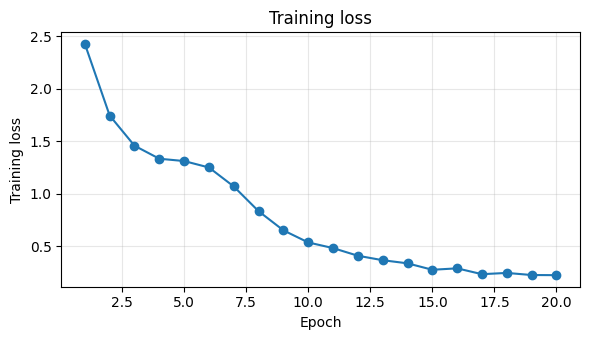

In [13]:
# train on full training set and scored on test set
model, history, lg, yt = fit(train_df, test_df, K, args, device, "final",
                             eval_each_epoch=False)
hist_df = pd.DataFrame(history)
hist_df.to_csv(out / "final_train_history.csv", index=False)

plt.figure(figsize=(6, 3.5))
plt.plot(hist_df["epoch"], hist_df["train_loss"], marker="o")
plt.xlabel("Epoch"); plt.ylabel("Training loss"); plt.title("Training loss")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 10. Held-out test results

In [14]:
# performance metrics
metrics = summarize(lg, yt)
pred = lg.argmax(1).numpy()
y_true = yt.numpy()

print("================ HELD-OUT TEST RESULTS ================")
print(f"Top-1 accuracy : {metrics['top1']:.4f}")
print(f"Top-3 accuracy : {metrics['top3']:.4f}")
print(f"Balanced acc.  : {metrics['balanced_acc']:.4f}")
print(f"Macro F1       : {metrics['macro_f1']:.4f}")
print(f"Finish line (top-1 > {FINISH_LINE:.0%}): "
      f"{'REACHED' if metrics['top1'] > FINISH_LINE else 'NOT reached'}\n")

# per-class precision
report_txt = classification_report(y_true, pred, labels=list(range(K)),
                                   target_names=classes, zero_division=0, digits=3)
print(report_txt)

================ HELD-OUT TEST RESULTS ================
Top-1 accuracy : 0.6410
Top-3 accuracy : 0.9423
Balanced acc.  : 0.5660
Macro F1       : 0.5954
Finish line (top-1 > 85%): NOT reached

                                  precision    recall  f1-score   support

15th Century (Unspecified Style)      0.800     0.615     0.696        13
16th Century (Unspecified Style)      0.577     0.714     0.638        21
17th Century (Unspecified Style)      0.444     0.432     0.438        37
18th Century (Unspecified Style)      0.688     0.647     0.667        51
19th Century (Unspecified Style)      0.528     0.671     0.591        70
                     Chinese Art      0.848     0.966     0.903        29
                        Folk Art      0.667     0.500     0.571         4
                   Impressionism      0.857     0.600     0.706        30
                    Japanese Art      0.923     0.800     0.857        15
                       Modernism      1.000     0.333     0.500    

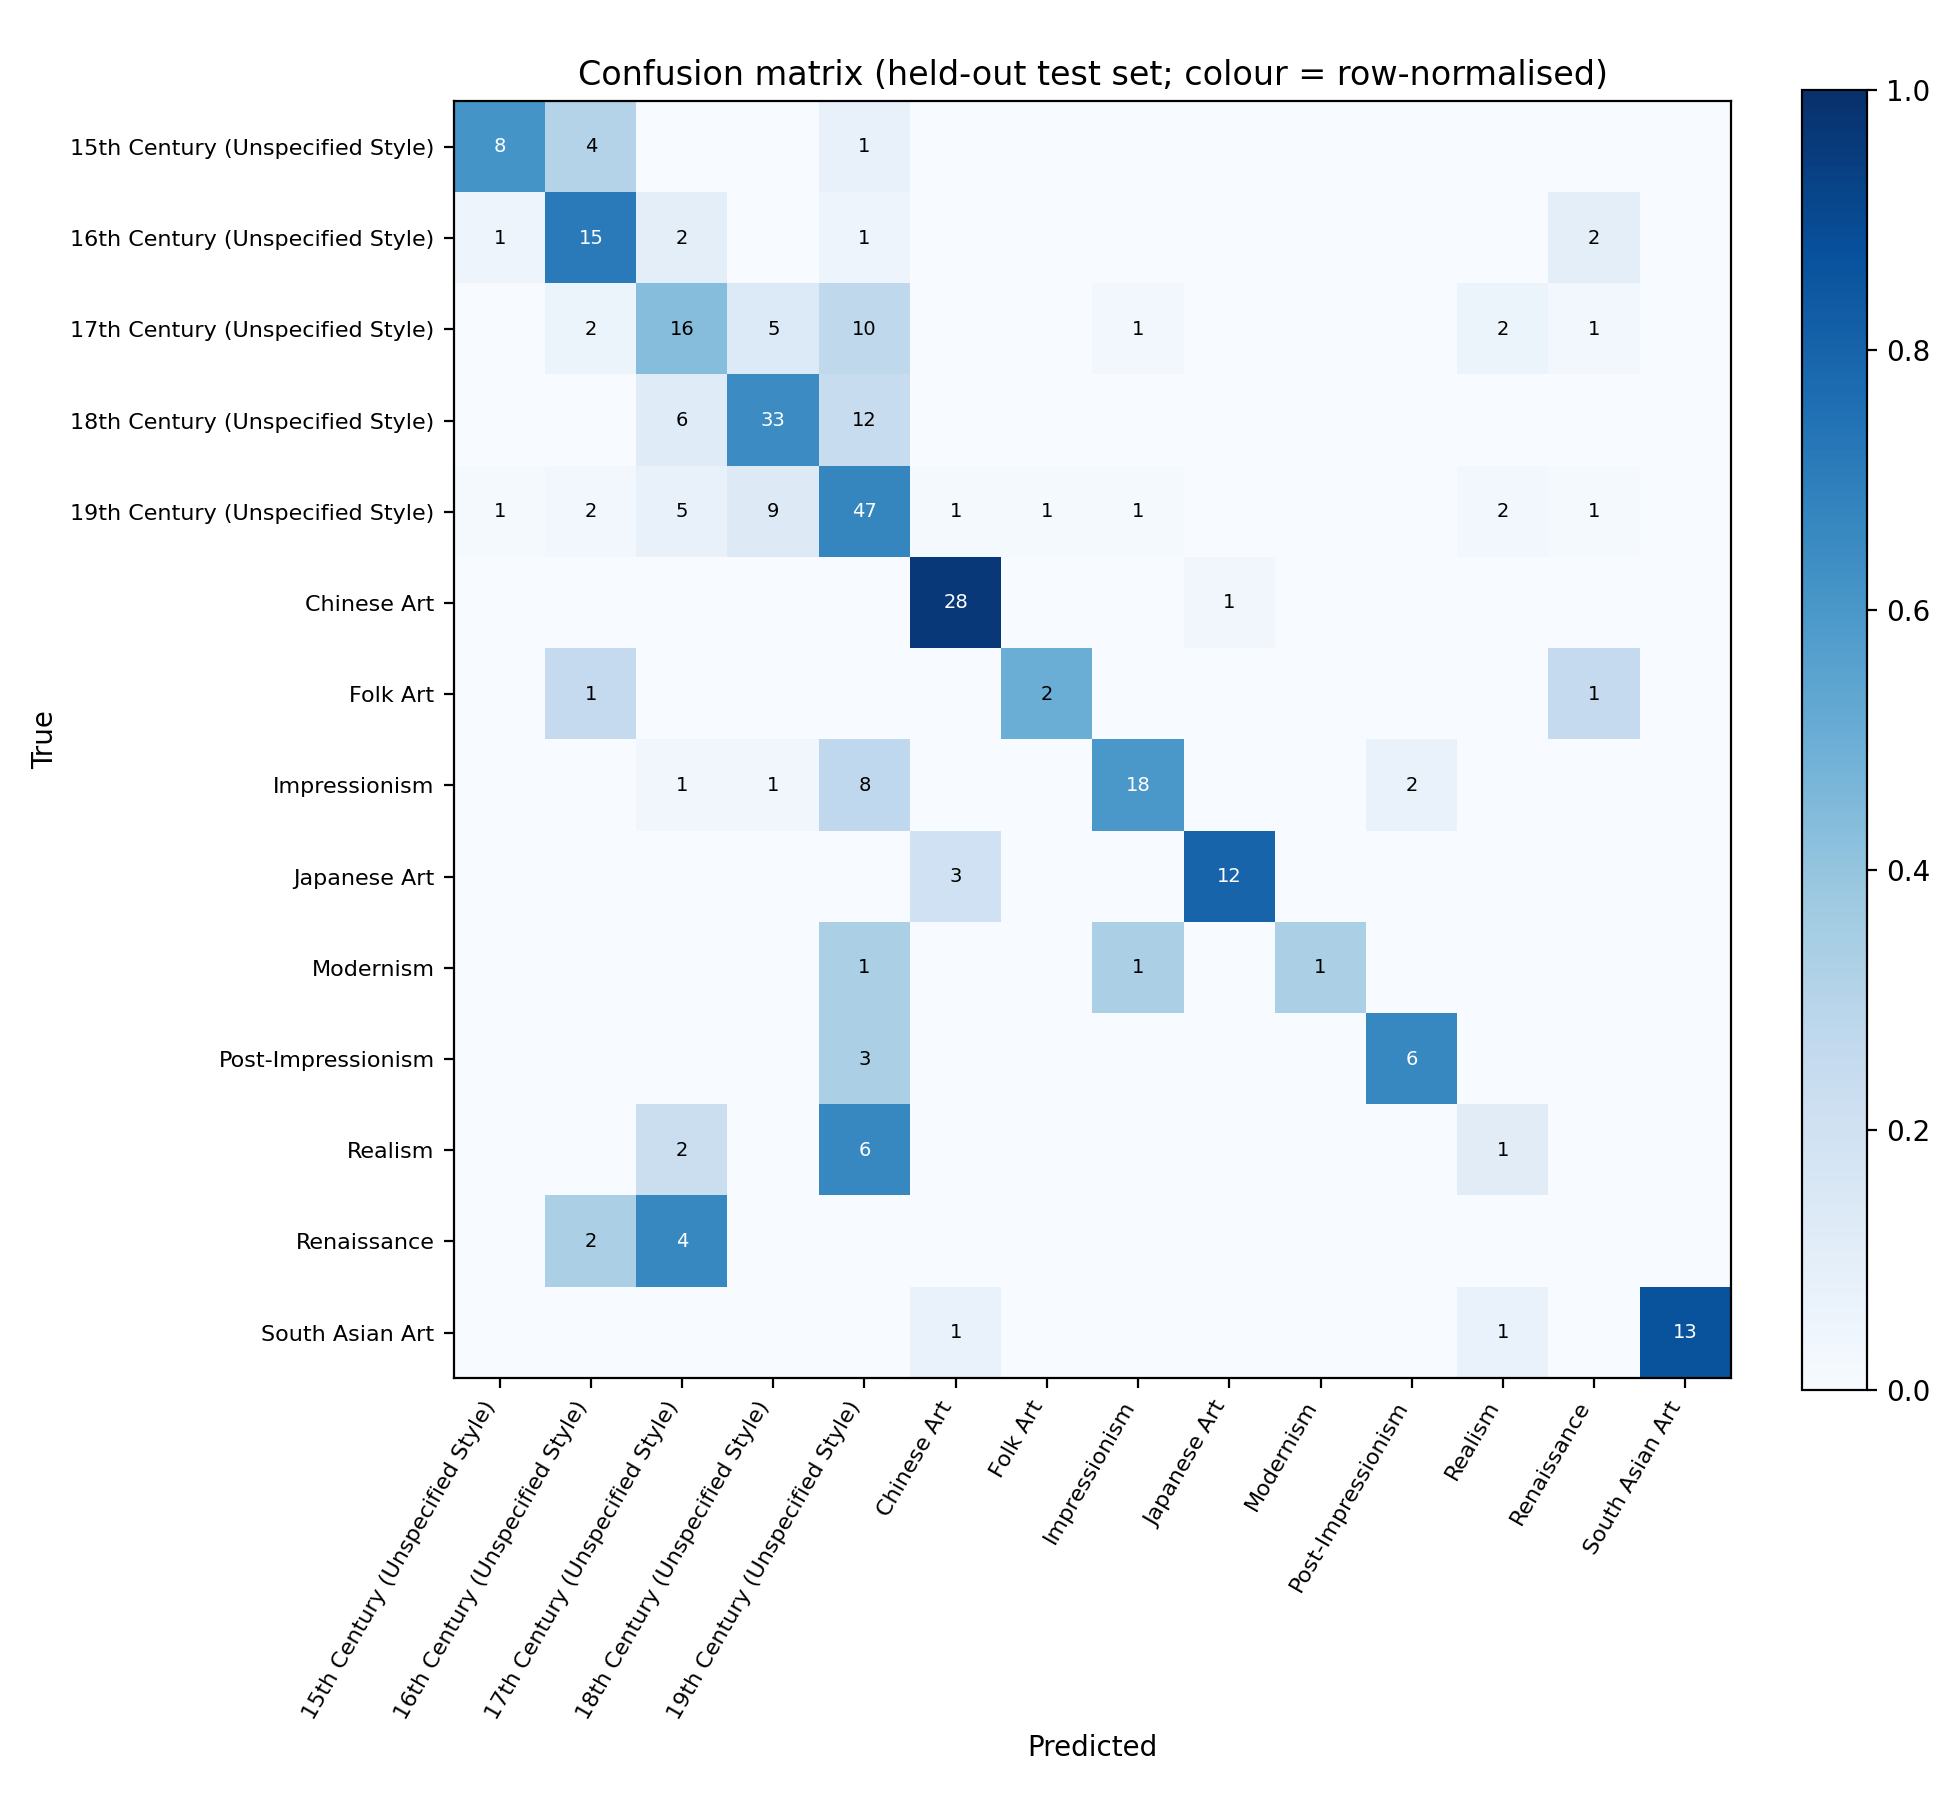

In [15]:
# confusion matrix, rows are true movement + columns are predicted movement
cm = confusion_matrix(y_true, pred, labels=list(range(K)))
plot_confusion(cm, classes, out / "confusion_matrix.png")
display(IPyImage(filename=str(out / "confusion_matrix.png")))

In [16]:
# Save metrics, predictions, and the trained model
pd.DataFrame(cm, index=classes, columns=classes).to_csv(out / "confusion_matrix.csv")
(out / "classification_report.txt").write_text(report_txt)
(out / "test_metrics.json").write_text(json.dumps(
    {**metrics, "finish_line_reached": metrics["top1"] > FINISH_LINE,
     "n_train": len(train_df), "n_test": len(test_df), "classes": classes,
     "args": vars(args)}, indent=2))

top3 = lg.topk(min(3, K), dim=1).indices.numpy()
pred_df = test_df.drop(columns=["path"]).copy()
pred_df["pred"] = [classes[i] for i in pred]
pred_df["correct"] = pred == y_true
for r in range(top3.shape[1]):
    pred_df[f"top{r + 1}"] = [classes[i] for i in top3[:, r]]
pred_df.to_csv(out / "test_predictions.csv", index=False)

torch.save({"state_dict": model.state_dict(), "classes": classes,
            "model": args.model, "img_size": args.img_size}, out / "convnext_art_movement.pt")
print(f"Saved model + results to {out.resolve()}")

Saved model + results to /content/outputs


## 11. Grad-CAM
Heatmaps of the last ConvNeXt stage for a random sample of test images, explaining the model's own prediction. Check that attention lands on the painting's content and brushwork rather than frames, borders, or labels.

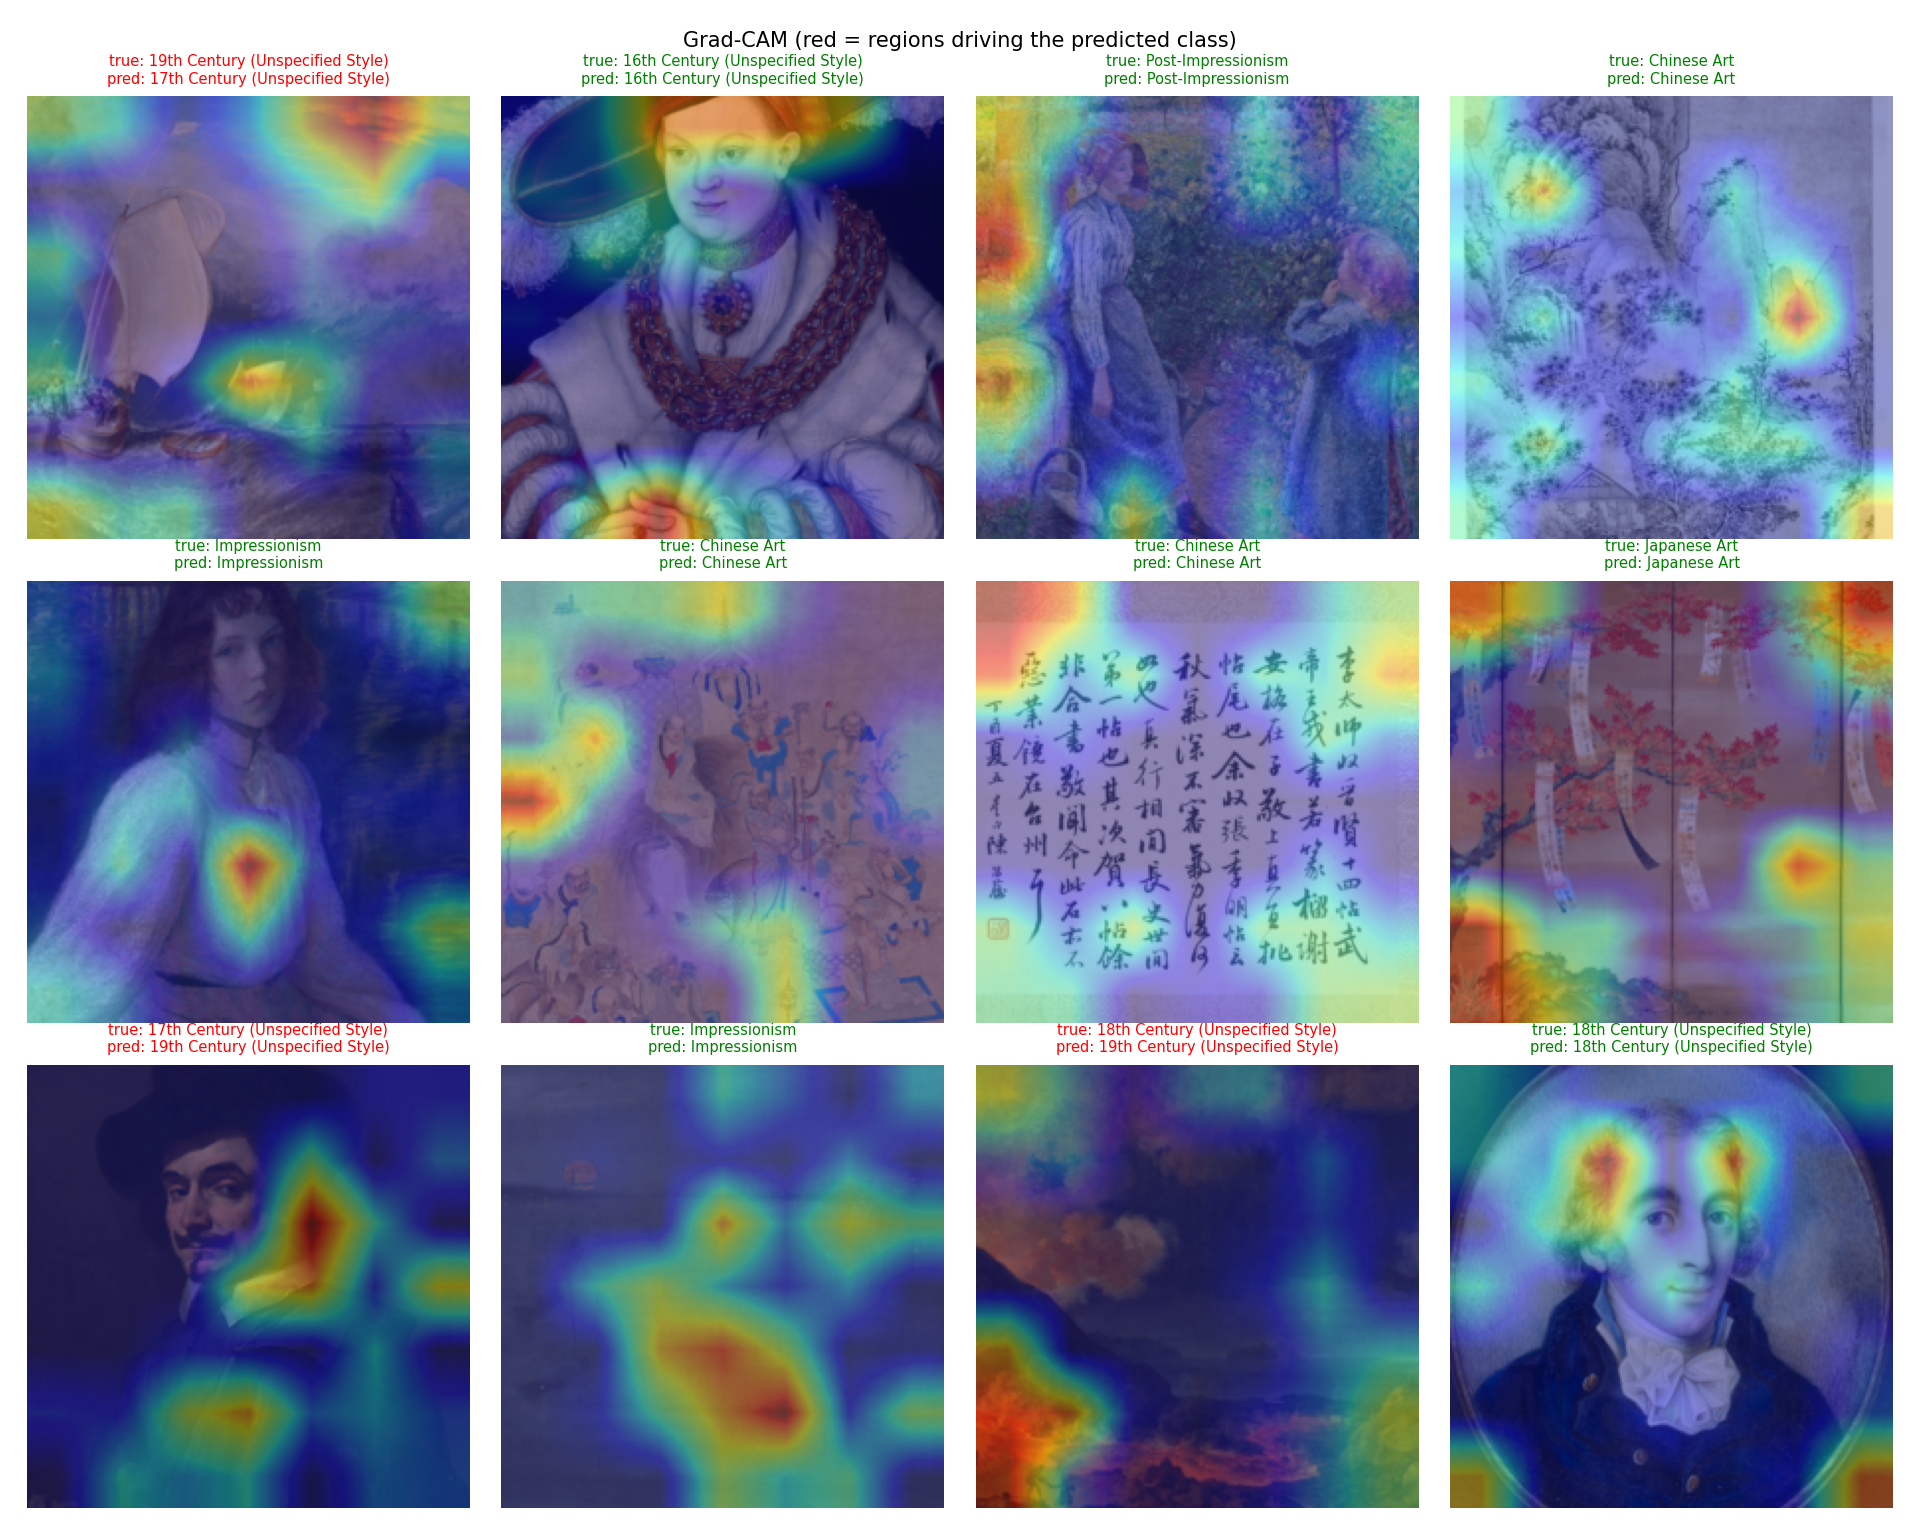

In [17]:
if args.gradcam > 0:
    grad_cam_figure(model, test_df, classes, pred, args, device, out / "gradcam.png")
    display(IPyImage(filename=str(out / "gradcam.png")))

In [18]:
import shutil
from google.colab import files

# zip and download outputs
shutil.make_archive('model_outputs', 'zip', '/content/outputs')
files.download('model_outputs.zip')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
shutil.make_archive('images', 'zip', '/content/images')
files.download('images.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>